# Online Shopper Purchase Prediction

**Problem.** An online store wants to know, while a visitor is still browsing, whether the
session will end in a purchase. With that probability, the marketing or product team can
act: offer a coupon or open a chat only for undecided visitors, without bothering the ones
who were going to buy anyway. The model takes session data (pages visited, time spent,
exit rate, month, visitor type, ...) and returns the probability of a purchase (column
`Revenue`).

**Contents:**

1. Data preparation
2. Exploratory data analysis (EDA) and feature importance
3. Baseline: logistic regression
4. Decision tree
5. Random forest
6. XGBoost
7. Model comparison and selection
8. Final model and test score
9. Feature importance of the final model

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('data/online_shoppers_intention.csv')
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 1. Data preparation

Three adjustments first:

- **Lowercase column names**, to avoid typos like `ProductRelated` vs `productrelated`.
- **`revenue` and `weekend` are `True`/`False`.** Models need numbers, so they become 1 and 0.
- **`operatingsystems`, `browser`, `region` and `traffictype` look numeric, but they are codes.**
  Browser 2 is not "twice" browser 1. Kept as numbers, logistic regression would assume an
  order between them. Converted to strings, the `DictVectorizer` (section 3) creates one
  0/1 column per code (one-hot encoding).

In [3]:
df.columns = df.columns.str.lower()

df['revenue'] = df['revenue'].astype(int)
df['weekend'] = df['weekend'].astype(int)

# category codes: converted to strings so they are one-hot encoded
for c in ['operatingsystems', 'browser', 'region', 'traffictype']:
    df[c] = df[c].astype(str)

df.dtypes

administrative               int64
administrative_duration    float64
informational                int64
informational_duration     float64
productrelated               int64
productrelated_duration    float64
bouncerates                float64
exitrates                  float64
pagevalues                 float64
specialday                 float64
month                          str
operatingsystems               str
browser                        str
region                         str
traffictype                    str
visitortype                    str
weekend                      int64
revenue                      int64
dtype: object

### Missing values and duplicates

In [4]:
print('missing values:', df.isnull().sum().sum())
print('duplicated rows:', df.duplicated().sum())

missing values: 0
duplicated rows: 125


There are no missing values. There are 125 rows that are exact copies of other rows across
all 18 columns. They add no information and can bias the evaluation: if one copy lands in
the training set and the other in the test set, the model has already "seen" the test
answer. We remove them.

In [5]:
df = df.drop_duplicates().reset_index(drop=True)
len(df)

12205

### Column lists

Selecting text columns with `df.dtypes == 'object'` does not work in pandas 3: the text
dtype is now `str` and the filter returns nothing. With this few columns, writing the
lists by hand is simpler and clearer.

In [6]:
numerical = [
    'administrative', 'administrative_duration',
    'informational', 'informational_duration',
    'productrelated', 'productrelated_duration',
    'bouncerates', 'exitrates', 'pagevalues', 'specialday', 'weekend',
]
categorical = [
    'month', 'operatingsystems', 'browser', 'region', 'traffictype', 'visitortype',
]

df[categorical].nunique()

month               10
operatingsystems     8
browser             13
region               9
traffictype         20
visitortype          3
dtype: int64

### Train / validation / test split

- **Train (60%):** where the models learn.
- **Validation (20%):** where we compare models and tune parameters.
- **Test (20%):** kept aside until the end, for a final score on data that never influenced
  any decision.

`train_test_split` only splits in two, so we do it in two steps: first 20% for test, then
25% of the remaining 80% for validation (25% of 80% = 20% of the total). `random_state=1`
makes the split reproducible.

In [7]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train['revenue'].values
y_val = df_val['revenue'].values
y_test = df_test['revenue'].values

# remove the target from the feature tables
del df_train['revenue']
del df_val['revenue']
del df_test['revenue']

len(df_train), len(df_val), len(df_test)

(7323, 2441, 2441)

## 2. Exploratory data analysis (EDA)

The goal is to understand the data before modeling: value ranges, the target
distribution, and which features seem to help predict a purchase. We only use
`df_full_train` (train + validation, which still has the `revenue` column). The test set
stays out until the end.

### Ranges of the numerical features

In [8]:
df_full_train[numerical].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
administrative,9764.0,2.34,3.34,0.0,0.00,1.00,4.00,26.00
administrative_duration,9764.0,82.04,180.66,0.0,0.00,9.00,94.22,3398.75
informational,9764.0,0.50,1.26,0.0,0.00,0.00,0.00,24.00
informational_duration,9764.0,33.14,134.92,0.0,0.00,0.00,0.00,2549.38
productrelated,9764.0,32.07,45.40,0.0,7.00,18.00,38.00,705.00
productrelated_duration,9764.0,1212.00,1966.50,0.0,190.48,605.94,1475.22,63973.52
bouncerates,9764.0,0.02,0.05,0.0,0.00,0.00,0.02,0.20
exitrates,9764.0,0.04,0.05,0.0,0.01,0.02,0.05,0.20
pagevalues,9764.0,5.91,18.49,0.0,0.00,0.00,0.00,361.76
specialday,9764.0,0.06,0.20,0.0,0.00,0.00,0.00,1.00


**Conclusion.** The durations are highly skewed: `productrelated_duration` has a mean of
about 1,200 seconds but goes up to almost 64,000 (around 18 hours, probably a tab left
open). The median of `pagevalues` is 0, so most sessions never visit pages that usually
lead to a purchase. `bouncerates` and `exitrates` stay between 0 and 0.2. Such different
scales do not affect tree-based models, but they can affect logistic regression.

### Target: how many sessions end in a purchase?

In [9]:
df_full_train['revenue'].value_counts(normalize=True).round(3)

revenue
0    0.846
1    0.154
Name: proportion, dtype: float64

**Conclusion.** Only 15.4% of the sessions end in a purchase. The dataset is
**imbalanced**: a model that always answers "no purchase" is right 85% of the time
without learning anything. Accuracy is misleading here, so we compare models with
**ROC AUC** (section 3).

### Purchase rate by category

For each category value, we compare the group's purchase rate with the global rate. The
`risk` column is the ratio of the two: above 1, the group buys more than average; below 1,
it buys less.

In [10]:
global_rate = df_full_train['revenue'].mean()

for c in categorical:
    df_group = df_full_train.groupby(c)['revenue'].agg(['mean', 'count'])
    df_group['risk'] = df_group['mean'] / global_rate
    print(c)
    display(df_group.sort_values('mean', ascending=False).head().round(3))

month


,mean,count,risk
month,,,
Nov,0.248,2386,1.613
Oct,0.205,458,1.337
Sep,0.190,348,1.235
Aug,0.168,352,1.092
Jul,0.158,361,1.028


operatingsystems


,mean,count,risk
operatingsystems,,,
5,0.200,5,1.303
8,0.190,63,1.241
2,0.175,5224,1.142
4,0.164,377,1.071
1,0.144,2024,0.937


browser


,mean,count,risk
browser,,,
12,0.333,9,2.171
13,0.213,47,1.386
10,0.210,124,1.366
11,0.200,5,1.303
5,0.184,354,1.196


... (2 outputs left out)

traffictype


,mean,count,risk
traffictype,,,
16,0.500,2,3.257
8,0.270,270,1.761
7,0.250,28,1.628
20,0.227,154,1.480
2,0.215,3122,1.398


visitortype


,mean,count,risk
visitortype,,,
New_Visitor,0.248,1366,1.616
Other,0.147,68,0.958
Returning_Visitor,0.138,8330,0.899


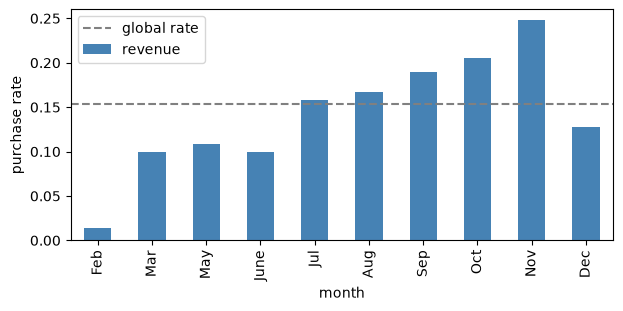

In [11]:
month_order = ['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
month_rate = df_full_train.groupby('month')['revenue'].mean().reindex(month_order)

month_rate.plot.bar(figsize=(7, 3), color='steelblue')
plt.axhline(global_rate, color='gray', linestyle='--', label='global rate')
plt.ylabel('purchase rate')
plt.legend()
plt.show()

**Conclusion.** November has the highest purchase rate (24.8%, 1.6 times the average),
probably because of Black Friday and holiday shopping. February has almost no purchases
(1.3%). May and March have many sessions but convert below average. New visitors buy more
(24.8%) than returning ones (13.8%). Some categories have very few sessions
(`traffictype` 16 has only 2), so their rates are not reliable.

The dataset covers only 10 months: January and April are missing, and June appears as
`June`, not `Jun`. This does not matter for one-hot encoding, since each string becomes
its own column.

### Mutual information of the categorical features

Mutual information measures how much knowing a feature's value reduces the uncertainty
about the target. The higher, the more useful the feature.

In [12]:
from sklearn.metrics import mutual_info_score


def mutual_info_revenue(series):
    return mutual_info_score(series, df_full_train['revenue'])


df_full_train[categorical].apply(mutual_info_revenue).sort_values(ascending=False).round(4)

traffictype         0.0151
month               0.0146
visitortype         0.0050
operatingsystems    0.0032
browser             0.0011
region              0.0005
dtype: float64

**Conclusion.** `traffictype` (where the visitor came from) and `month` are the most
informative categorical features. `region` and `browser` say almost nothing about a
purchase.

### Correlation of the numerical features with the target

Correlation ranges from -1 to 1. Positive: the higher the feature, the more purchases.
Negative: the higher the feature, the fewer purchases.

In [13]:
df_full_train[numerical].corrwith(df_full_train['revenue']).sort_values(ascending=False).round(3)

pagevalues                 0.487
productrelated             0.159
productrelated_duration    0.153
administrative             0.146
administrative_duration    0.095
informational              0.093
informational_duration     0.071
weekend                    0.027
specialday                -0.083
bouncerates               -0.145
exitrates                 -0.202
dtype: float64

In [14]:
has_page_value = df_full_train['pagevalues'] > 0
print('sessions with pagevalues > 0:', round(has_page_value.mean(), 3))
df_full_train.groupby(has_page_value)['revenue'].mean().round(3)

sessions with pagevalues > 0: 0.224


pagevalues
False    0.038
True     0.556
Name: revenue, dtype: float64

**Conclusion.** `pagevalues` is by far the strongest feature (correlation of 0.49). It is
the average value, computed by Google Analytics, of the pages the visitor saw: pages that
often come before a purchase are worth more. Only 22% of the sessions have `pagevalues`
above 0, but their purchase rate is 56%, against 4% for the others. Viewing more product
pages (`productrelated`) also helps. High exit and bounce rates (`exitrates`,
`bouncerates`) indicate that the visitor leaves without buying.

## 3. Baseline: logistic regression

### One-hot encoding with `DictVectorizer`

scikit-learn models only accept numbers. `DictVectorizer` takes each row as a dictionary
and:

- keeps the numerical features as they are;
- creates a 0/1 column for each string value (`month=Nov`, `visitortype=New_Visitor`, ...).

`fit_transform` is used **only on the training set**, where it learns which columns
exist. Validation and test only use `transform`, so they get the same columns.

In [15]:
from sklearn.feature_extraction import DictVectorizer

features = numerical + categorical

train_dicts = df_train[features].to_dict(orient='records')
val_dicts = df_val[features].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

print('first session as a dictionary:')
print(train_dicts[0])
print()
print('matrix shape:', X_train.shape)

first session as a dictionary:
{'administrative': 1, 'administrative_duration': 4.75, 'informational': 2, 'informational_duration': 78.0, 'productrelated': 67, 'productrelated_duration': 1231.136508, 'bouncerates': 0.002985075, 'exitrates': 0.0110199, 'pagevalues': 0.0, 'specialday': 0.0, 'weekend': 0, 'month': 'Mar', 'operatingsystems': '2', 'browser': '6', 'region': '1', 'traffictype': '1', 'visitortype': 'Returning_Visitor'}

matrix shape: (7323, 72)


The 17 features became 72 columns: 11 numerical plus one column for each value of the 6
categorical features.

### Dummy model: why not accuracy

Before training, let's see how a model that always says "no purchase" scores.

In [16]:
from sklearn.metrics import accuracy_score, roc_auc_score

y_dummy = np.zeros(len(y_val))
print('accuracy:', round(accuracy_score(y_val, y_dummy), 3))
print('ROC AUC: ', roc_auc_score(y_val, y_dummy))

accuracy: 0.854
ROC AUC:  0.5


It is right 85% of the time without learning anything. Its **ROC AUC** is 0.5, the value
of a random guess.

ROC AUC answers this question: given one session that ended in a purchase and one that
did not, what is the chance that the model gives a higher probability to the first one?
It goes from 0.5 (random) to 1 (perfect) and does not depend on a threshold such as 0.5.
This is the metric we use from now on.

### First logistic regression

`predict_proba` returns two columns (probability of 0 and of 1). We take the second one,
`[:, 1]`, the probability of a purchase.

In [17]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]
print('ROC AUC: ', round(roc_auc_score(y_val, y_pred), 3))
print('accuracy:', round(accuracy_score(y_val, y_pred >= 0.5), 3))

ROC AUC:  0.883
accuracy: 0.88


An AUC of 0.883: the model already separates buyers from non-buyers well. Accuracy only
goes from 85% (dummy model) to 88%, which looks small, but AUC shows the real gap: from
0.5 to 0.88.

### Tuning `C` with cross-validation

`C` controls regularization: **the smaller `C`, the more the model is constrained** and
the less it fits the details of the training data.

Instead of relying on a single validation split, cross-validation (`KFold`) splits
`df_full_train` into 5 parts, trains on 4 and evaluates on the 5th, rotating 5 times. The
mean tells which `C` is best, and the standard deviation shows how much the result varies.

In [18]:
from sklearn.model_selection import KFold


def train_lr(df, y, C):
    dicts = df[features].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(dicts)
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y)
    return dv, model


def predict_lr(df, dv, model):
    dicts = df[features].to_dict(orient='records')
    X = dv.transform(dicts)
    return model.predict_proba(X)[:, 1]


kfold = KFold(n_splits=5, shuffle=True, random_state=1)

for C in [0.001, 0.01, 0.1, 1, 10]:
    aucs = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]
        dv_cv, model_cv = train_lr(df_tr, df_tr['revenue'].values, C)
        y_pred = predict_lr(df_va, dv_cv, model_cv)
        aucs.append(roc_auc_score(df_va['revenue'].values, y_pred))
    print(f'C={C:<6} AUC = {np.mean(aucs):.3f} ± {np.std(aucs):.3f}')

C=0.001  AUC = 0.845 ± 0.025


C=0.01   AUC = 0.898 ± 0.009


C=0.1    AUC = 0.895 ± 0.007


C=1      AUC = 0.893 ± 0.006


C=10     AUC = 0.891 ± 0.006


**Conclusion.** `C=0.01` is the best (0.898). A small `C` helps because the features have
very different scales (see the durations in the EDA), and regularization keeps the model
from giving them too much weight. We keep `C=0.01` and store its validation AUC for the
final comparison.

In [19]:
model = LogisticRegression(solver='liblinear', C=0.01, max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict_proba(X_val)[:, 1]

scores = {}
scores['logistic regression'] = roc_auc_score(y_val, y_pred)
round(scores['logistic regression'], 3)

0.891

## 4. Decision tree

A tree asks questions in sequence ("`pagevalues` > 0?", "`month` = Nov?") until it reaches
an answer. Two parameters control its size:

- **`max_depth`:** the maximum number of questions in sequence.
- **`min_samples_leaf`:** the minimum number of sessions in each leaf (the end of a path).

Trees that are too large memorize the training data (**overfitting**) and do poorly on
validation.

In [20]:
from sklearn.tree import DecisionTreeClassifier

for depth in [1, 2, 3, 4, 5, 6, 8, 10, 15, None]:
    dt = DecisionTreeClassifier(max_depth=depth, random_state=1)
    dt.fit(X_train, y_train)
    auc = roc_auc_score(y_val, dt.predict_proba(X_val)[:, 1])
    print(f'max_depth={str(depth):<5} AUC = {auc:.3f}')

max_depth=1     AUC = 0.831
max_depth=2     AUC = 0.878
max_depth=3     AUC = 0.890
max_depth=4     AUC = 0.896
max_depth=5     AUC = 0.897
max_depth=6     AUC = 0.895
max_depth=8     AUC = 0.841
max_depth=10    AUC = 0.782
max_depth=15    AUC = 0.769
max_depth=None  AUC = 0.742


With no limit (`None`), AUC drops to 0.742: the tree memorized the training data. The best
depths are between 4 and 6. Now, for a few depths, we vary `min_samples_leaf`:

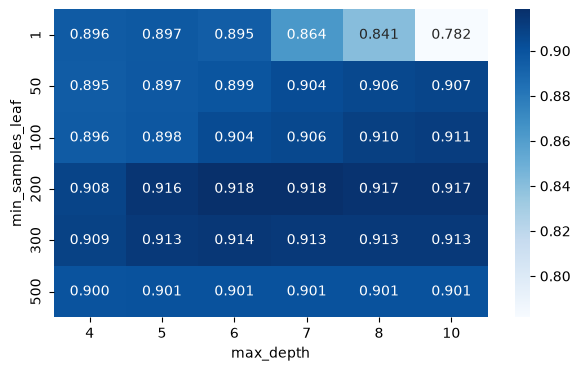

In [21]:
rows = []
for depth in [4, 5, 6, 7, 8, 10]:
    for leaf in [1, 50, 100, 200, 300, 500]:
        dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=1)
        dt.fit(X_train, y_train)
        auc = roc_auc_score(y_val, dt.predict_proba(X_val)[:, 1])
        rows.append((depth, leaf, auc))

df_scores = pd.DataFrame(rows, columns=['max_depth', 'min_samples_leaf', 'auc'])
pivot = df_scores.pivot(index='min_samples_leaf', columns='max_depth', values='auc')

plt.figure(figsize=(7, 4))
sns.heatmap(pivot, annot=True, fmt='.3f', cmap='Blues')
plt.show()

**Conclusion.** Large leaves (200 sessions) help a lot: each leaf needs many sessions to
give a stable probability. The best combination is `max_depth=6` with
`min_samples_leaf=200`, with an AUC of 0.918, already above logistic regression.

In [22]:
dt = DecisionTreeClassifier(max_depth=6, min_samples_leaf=200, random_state=1)
dt.fit(X_train, y_train)
scores['decision tree'] = roc_auc_score(y_val, dt.predict_proba(X_val)[:, 1])
round(scores['decision tree'], 3)

0.918

## 5. Random forest

A random forest trains many trees, each on a different sample of sessions and features,
and averages their answers. Different trees make different mistakes, so the average makes
fewer mistakes than a single tree.

First, the number of trees (`n_estimators`):

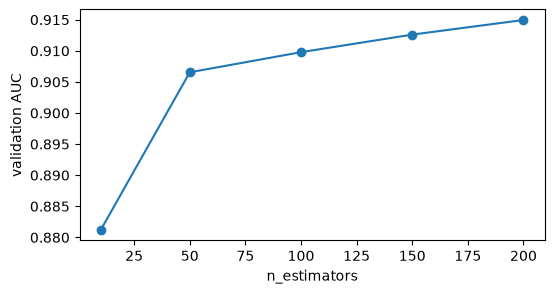

In [23]:
from sklearn.ensemble import RandomForestClassifier

n_values = [10, 50, 100, 150, 200]
aucs = []
for n in n_values:
    rf = RandomForestClassifier(n_estimators=n, random_state=1, n_jobs=-1)
    rf.fit(X_train, y_train)
    aucs.append(roc_auc_score(y_val, rf.predict_proba(X_val)[:, 1]))

plt.figure(figsize=(6, 3))
plt.plot(n_values, aucs, marker='o')
plt.xlabel('n_estimators')
plt.ylabel('validation AUC')
plt.show()

AUC keeps increasing up to 200 trees, with diminishing gains. We keep 200 and tune
`max_depth` and `min_samples_leaf`:

In [24]:
rows = []
for depth in [5, 10, 15, 20]:
    for leaf in [1, 3, 5, 10, 50]:
        rf = RandomForestClassifier(n_estimators=200, max_depth=depth,
                                    min_samples_leaf=leaf, random_state=1, n_jobs=-1)
        rf.fit(X_train, y_train)
        auc = roc_auc_score(y_val, rf.predict_proba(X_val)[:, 1])
        rows.append((depth, leaf, auc))

df_scores = pd.DataFrame(rows, columns=['max_depth', 'min_samples_leaf', 'auc'])
df_scores.pivot(index='min_samples_leaf', columns='max_depth', values='auc').round(3)

max_depth,5,10,15,20
min_samples_leaf,,,,
1,0.911,0.916,0.919,0.917
3,0.911,0.918,0.921,0.917
5,0.911,0.918,0.919,0.920
10,0.911,0.917,0.918,0.919
50,0.909,0.912,0.912,0.912


**Conclusion.** The best combination is `max_depth=15` with `min_samples_leaf=3`, with an
AUC of 0.921. The differences between combinations are small: a random forest is not very
sensitive to its parameters, since averaging many trees corrects the excesses of each one.

In [25]:
rf = RandomForestClassifier(n_estimators=200, max_depth=15, min_samples_leaf=3,
                            random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)
scores['random forest'] = roc_auc_score(y_val, rf.predict_proba(X_val)[:, 1])
round(scores['random forest'], 3)

0.921

## 6. XGBoost

In gradient boosting, trees are trained **in sequence**: each new tree tries to correct the
errors of the previous ones. The main parameters:

- **`learning_rate`** (`eta`): how much each new tree corrects. Small = learns slowly, but more carefully.
- **`n_estimators`** (`num_boost_round`): the number of trees.
- **`max_depth`:** the depth of each tree. Shallow trees usually work well in boosting.
- **`min_child_weight`:** similar to `min_samples_leaf`, prevents leaves with few sessions.

We use `XGBClassifier`, the scikit-learn interface of XGBoost (`fit`, `predict_proba`),
instead of `xgb.train` with a `DMatrix`. It fits in a pipeline together with the
`DictVectorizer`, which keeps `train.py` and `predict.py` simple.

We tune one parameter at a time. First `learning_rate` together with the number of trees,
because the two go together.

In [26]:
from xgboost import XGBClassifier


def xgb_auc(**params):
    model = XGBClassifier(random_state=1, n_jobs=4, **params)
    model.fit(X_train, y_train)
    return roc_auc_score(y_val, model.predict_proba(X_val)[:, 1])


rows = []
for eta in [0.01, 0.05, 0.1, 0.3]:
    for n in [50, 100, 200, 500]:
        rows.append((eta, n, xgb_auc(learning_rate=eta, n_estimators=n, max_depth=6)))

df_scores = pd.DataFrame(rows, columns=['learning_rate', 'n_estimators', 'auc'])
df_scores.pivot(index='n_estimators', columns='learning_rate', values='auc').round(4)

learning_rate,0.01,0.05,0.10,0.30
n_estimators,,,,
50,0.9074,0.9241,0.9259,0.9158
100,0.9178,0.9250,0.9245,0.9113
200,0.9227,0.9236,0.9199,0.9086
500,0.9255,0.9184,0.9147,0.9045


With a high `learning_rate` (0.3), more trees make the result worse: the model starts to
memorize the training data. The highest value in the table is 0.1 with 50 trees (0.926),
but it drops quickly as trees are added. With 0.05 the result is almost the same and stays
stable between 50 and 200 trees, which is safer. We fix 0.05 and tune `max_depth`:

In [27]:
rows = []
for depth in [3, 4, 6, 8]:
    for n in [50, 100, 200, 300]:
        rows.append((depth, n, xgb_auc(learning_rate=0.05, n_estimators=n, max_depth=depth)))

df_scores = pd.DataFrame(rows, columns=['max_depth', 'n_estimators', 'auc'])
df_scores.pivot(index='n_estimators', columns='max_depth', values='auc').round(4)

max_depth,3,4,6,8
n_estimators,,,,
50,0.9209,0.9241,0.9241,0.9226
100,0.9251,0.9260,0.9250,0.9231
200,0.9263,0.9263,0.9236,0.9223
300,0.9257,0.9248,0.9216,0.9206


Shallow trees (3 or 4 levels) do better, as expected in boosting. We fix `max_depth=4` and
tune `min_child_weight`:

In [28]:
rows = []
for w in [1, 5, 10, 20, 30]:
    for n in [100, 200, 300]:
        rows.append((w, n, xgb_auc(learning_rate=0.05, n_estimators=n, max_depth=4,
                                   min_child_weight=w)))

df_scores = pd.DataFrame(rows, columns=['min_child_weight', 'n_estimators', 'auc'])
df_scores.pivot(index='n_estimators', columns='min_child_weight', values='auc').round(4)

min_child_weight,1,5,10,20,30
n_estimators,,,,,
100,0.9260,0.9254,0.9264,0.9267,0.9248
200,0.9263,0.9262,0.9272,0.9272,0.9266
300,0.9248,0.9250,0.9264,0.9265,0.9267


**Conclusion.** `min_child_weight=10` with 200 trees gives the best AUC (0.927), tied with
20. We keep 10, the less restrictive of the two. Final XGBoost configuration:
`learning_rate=0.05`, `max_depth=4`, `min_child_weight=10`, `n_estimators=200`.

In [29]:
xgb_params = dict(learning_rate=0.05, max_depth=4, min_child_weight=10, n_estimators=200)
scores['XGBoost'] = xgb_auc(**xgb_params)
round(scores['XGBoost'], 3)

0.927

## 7. Model comparison and selection

In [30]:
df_results = pd.DataFrame(list(scores.items()), columns=['model', 'validation AUC'])
df_results.sort_values('validation AUC', ascending=False).round(3)

,model,validation AUC
3,XGBoost,0.927
2,random forest,0.921
1,decision tree,0.918
0,logistic regression,0.891


**Conclusion.** XGBoost is the best, closely followed by the random forest. All three
tree-based models beat logistic regression, because they capture combinations (for
example, high `pagevalues` **and** November) that a linear model does not capture on its
own.

We select **XGBoost**.

## 8. Final model and test score

With the model selected, we retrain it on **train + validation** (`df_full_train`): more
data, a slightly better model. Only now do we use the test set, once, to get an honest
estimate of how the model will perform on new data.

In [31]:
y_full_train = df_full_train['revenue'].values

full_train_dicts = df_full_train[features].to_dict(orient='records')
test_dicts = df_test[features].to_dict(orient='records')

dv_final = DictVectorizer(sparse=False)
X_full_train = dv_final.fit_transform(full_train_dicts)
X_test = dv_final.transform(test_dicts)

final_model = XGBClassifier(random_state=1, n_jobs=4, **xgb_params)
final_model.fit(X_full_train, y_full_train)

y_pred_test = final_model.predict_proba(X_test)[:, 1]
round(roc_auc_score(y_test, y_pred_test), 3)

0.937

**Conclusion.** A test AUC of 0.937, slightly above validation (0.927). The final model was
trained on more data, and small variations between samples are normal. What matters is
that the score **did not drop**: choosing parameters on the validation set did not overfit
to it, and the model works on sessions it has never seen.

## 9. Feature importance of the final model

XGBoost records how much each column contributed to the decisions of the trees.

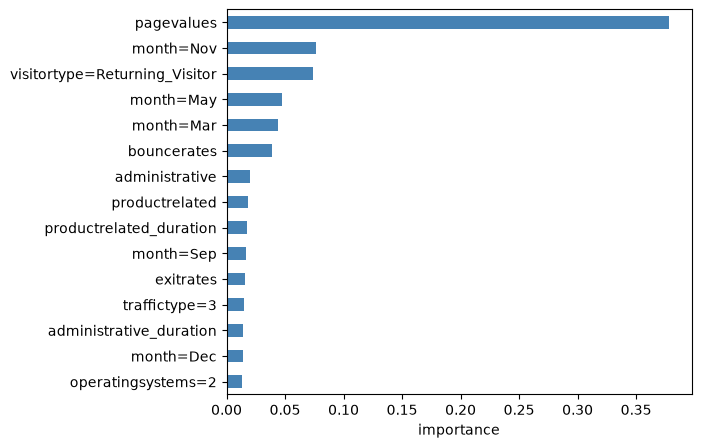

In [32]:
importances = pd.Series(final_model.feature_importances_,
                        index=dv_final.get_feature_names_out())

importances.sort_values().tail(15).plot.barh(figsize=(6, 5), color='steelblue')
plt.xlabel('importance')
plt.show()

**Conclusion.** `pagevalues` accounts for more than a third of the importance (0.38),
confirming what the correlation showed in the EDA. Next come the month (`month=Nov`,
`May`, `Mar`) and the visitor type (`visitortype=Returning_Visitor`), the same features
that stood out in the purchase rate by category. `region` and `browser`, which had almost
zero mutual information, are not among the top 15.

## Next steps

The notebook was used to explore and choose. The rest of the project turns it into code
that runs on its own:

1. **`train.py`:** repeats only the data preparation and the training of the final model, and saves it to `model.bin`.
2. **`predict.py`:** loads `model.bin` and serves predictions through a web API (FastAPI).
3. **`Dockerfile`:** packages the API in a container.